# Factor Timing with Machine-Learning IC Forecasts

The original course project (`original/`) predicted each month which of three factors (book-to-market,
size, momentum) would work best, and traded a long-short portfolio on that factor. It reported win rates
above 90% against the market and annualized Sharpe ratios above 5.

This notebook shows that those results came from a data alignment error, fixes it, and re-evaluates the
same strategy:

1. **The error.** Momentum was matched with the stock return from 12 months earlier, a return that is part
   of the momentum calculation itself. This made momentum look almost perfectly predictive.
2. **Reproduction.** Rebuilding the original pipeline in Python reproduces the original results.
3. **Corrected evaluation.** With proper alignment, the same models (OLS, random forest, NN1 to NN5) are
   evaluated with walk-forward forecasts, out-of-sample R², and risk-adjusted returns.

Data: monthly TEJ data for 1,848 Taiwan-listed common stocks, January 2000 to December 2024. The data is
licensed and not included; see the README for the expected format.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.backtest import backtest, performance
from src.factors import FACTORS, compute_factors, load_panels, original_factors
from src.ic import ic_table
from src.models import baseline_predictions, model_factories, oos_r2, predict_all

warnings.filterwarnings('ignore', category=UserWarning)
FIG_DIR, CACHE_DIR = Path('figures'), Path('cache')
FIG_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Data and factors

In [2]:
panels, twii = load_panels()
fixed = compute_factors(panels)        # correct alignment, missing values left out
original = original_factors(panels)    # original spreadsheet logic, including its errors

ic_fixed = ic_table(fixed)
ic_original = ic_table(original)
months = list(ic_fixed.index)
TEST = months[months.index('2013/12'):months.index('2024/11') + 1]
print(f'{panels["close"].shape[0]:,} stocks, {len(months)} months; test period {TEST[0]} to {TEST[-1]} ({len(TEST)} months)')

1,848 stocks, 300 months; test period 2013/12 to 2024/11 (132 months)


## 2. The momentum alignment error

The IC is the cross-sectional correlation between a factor at month *t* and the stock return from *t* to
*t*+1. In the original spreadsheet the momentum sheet started 12 months later than the return sheet, and the
two were matched by column position, so momentum at *t* was correlated with the return from *t*−12 to *t*−11.

In [3]:
def ic_summary(ic):
    return pd.DataFrame({'Mean IC': ic.mean(), 'Mean |IC|': ic.abs().mean(), 'Share of months > 0': (ic > 0).mean()})

summary = pd.concat({'Original': ic_summary(ic_original.loc[TEST]), 'Corrected': ic_summary(ic_fixed.loc[TEST])}, axis=1)
summary.round(3)

Original                               Corrected            \
      Mean IC Mean |IC| Share of months > 0   Mean IC Mean |IC|   
bm      0.037     0.074               0.652     0.035     0.073   
size   -0.027     0.069               0.356    -0.029     0.070   
mom     0.304     0.304               1.000     0.002     0.080   

                          
     Share of months > 0  
bm                 0.652  
size               0.356  
mom                0.508

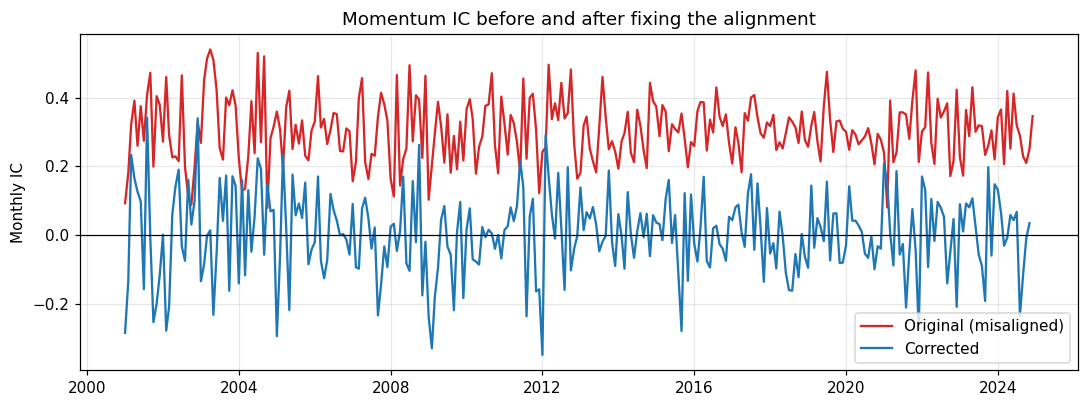

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
dates = pd.to_datetime(ic_fixed.index, format='%Y/%m')
ax.plot(dates, ic_original['mom'], color='tab:red', label='Original (misaligned)')
ax.plot(dates, ic_fixed['mom'], color='tab:blue', label='Corrected')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Monthly IC')
ax.set_title('Momentum IC before and after fixing the alignment')
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'momentum_ic.png', dpi=150)
plt.show()

## 3. Forecasting next month's IC

Each model is refitted every month with only the information available at that time, and predicts the IC of
the coming month for each factor. Two feature sets are compared:

- **Cross-section** (original design): the factor values of all 1,848 stocks in the previous month.
- **Lagged IC**: the 12 most recent monthly ICs of all three factors (36 features).

Neural networks use scikit-learn's `MLPRegressor` with the same layer sizes as the original Keras models
(NN1 = 32, NN2 = 32-16, ..., NN5 = 32-16-8-4-2) and are rebuilt every month. The random forest with 1,848 cross-sectional features is refitted once a year to
keep the running time reasonable (set `REFIT_EVERY = {}` in `src/models.py` to refit monthly). Results are
cached in `cache/`; the first run takes about 15 to 30 minutes.

In [5]:
def cached_predictions(tag, ic, pairs, feature_set):
    path = CACHE_DIR / f'predictions_{tag}.pkl'
    if path.exists():
        return pd.read_pickle(path)
    preds = predict_all(ic, pairs, TEST, feature_set)
    pd.to_pickle(preds, path)
    return preds


preds_cross = cached_predictions('cross_section', ic_fixed, fixed, 'cross_section')
preds_lagged = cached_predictions('lagged_ic', ic_fixed, fixed, 'lagged_ic')
preds_original = cached_predictions('original', ic_original, original, 'cross_section')

### Out-of-sample R²

`R2 vs zero` is the measure used in the original project (the benchmark predicts an IC of zero).
`R2 vs past mean` uses the average IC of the previous 12 months as the benchmark. Negative values mean the
model forecasts worse than the benchmark.

In [6]:
rows = []
for label, preds, ic in [('Original data', preds_original, ic_original),
                         ('Cross-section', preds_cross, ic_fixed),
                         ('Lagged IC', preds_lagged, ic_fixed)]:
    for model, pred in preds.items():
        rows.append({'Data / features': label, 'Model': model, **oos_r2(pred, ic, TEST)})
r2 = pd.DataFrame(rows).pivot(index='Model', columns='Data / features')
r2 = r2.reindex(list(model_factories()))
r2.round(3)

R2 vs zero                         R2 vs past mean  \
Data / features Cross-section Lagged IC Original data   Cross-section   
Model                                                                   
OLS                    -2.281    -0.210         0.451          -2.264   
RF                      0.053     0.045         0.828           0.057   
NN1                   -78.710    -3.372       -43.656         -78.321   
NN2                   -45.787    -0.101       -11.560         -45.559   
NN3                   -34.078    -1.542        -5.364         -33.907   
NN4                    -8.606    -0.619        -1.183          -8.559   
NN5                    -0.705    -0.024         0.577          -0.697   

                                         
Data / features Lagged IC Original data  
Model                                    
OLS                -0.204        -2.019  
RF                  0.049         0.057  
NN1                -3.350      -244.599  
NN2                -0.096       -68.079  
NN3                -1.529       -33.999  
NN4                -0.611       -11.004  
NN5                -0.019        -1.327

## 4. Backtest

Each month the factor with the largest absolute predicted IC is chosen. Stocks are sorted on that factor;
the strategy buys the top decile and shorts the bottom decile (reversed if the predicted IC is negative)
and holds for one month. Returns are equal-weighted simple returns without transaction costs.

Benchmarks:

- **Perfect foresight** uses the true IC of the coming month. It is impossible in practice and shows the
  upper limit of factor timing.
- **Past 12-month mean** chooses the factor using only the average of recent ICs.
- **Static** strategies always hold the same factor, to check whether timing adds anything.

In [7]:
def static(factor, sign):
    return pd.DataFrame({f: (sign if f == factor else 0.0) for f in FACTORS}, index=TEST)


strategies = {
    'Perfect foresight': baseline_predictions(ic_fixed, TEST)['Perfect foresight'],
    'Past 12-month mean': baseline_predictions(ic_fixed, TEST)['Past 12-month mean'],
    'Static: value (high bm)': static('bm', 1),
    'Static: small size': static('size', -1),
    'Static: momentum': static('mom', 1),
    **{f'{m} (cross-section)': p for m, p in preds_cross.items()},
    **{f'{m} (lagged IC)': p for m, p in preds_lagged.items()},
}

returns, picks = {}, {}
for name, pred in strategies.items():
    r, chosen = backtest(pred, fixed, groups=[10])
    returns[name], picks[name] = r[10], chosen

table = pd.DataFrame({name: performance(r) for name, r in returns.items()}).T
table['Months bm / size / mom'] = [
    ' / '.join(str((picks[n] == f).sum()) for f in FACTORS) for n in table.index]
table.round(3)

,Annual return,Annual volatility,Sharpe ratio,t-stat,Max drawdown,Hit rate,Months bm / size / mom
Perfect foresight,0.557,0.106,5.241,17.381,-0.011,0.977,42 / 39 / 51
Past 12-month mean,0.113,0.143,0.794,2.634,-0.317,0.621,55 / 52 / 25
Static: value (high bm),0.088,0.125,0.702,2.327,-0.193,0.606,132 / 0 / 0
Static: small size,0.261,0.132,1.984,6.581,-0.083,0.727,0 / 132 / 0
Static: momentum,0.052,0.130,0.400,1.328,-0.291,0.561,0 / 0 / 132
OLS (cross-section),0.035,0.127,0.276,0.914,-0.292,0.530,35 / 17 / 80
RF (cross-section),0.137,0.124,1.104,3.662,-0.122,0.652,104 / 28 / 0
NN1 (cross-section),-0.014,0.141,-0.102,-0.339,-0.394,0.470,49 / 40 / 43
NN2 (cross-section),0.014,0.135,0.101,0.333,-0.304,0.508,44 / 42 / 46
NN3 (cross-section),0.004,0.131,0.032,0.107,-0.320,0.508,54 / 30 / 48


In [8]:
# The original pipeline, reproduced: misaligned momentum, median-filled data, log returns
orig_rows = {}
for name, pred in {'Perfect foresight': ic_original.loc[TEST], **preds_original}.items():
    r, chosen = backtest(pred, original, groups=[10], simple=False)
    orig_rows[name] = {**performance(r[10]), 'Months choosing momentum': int((chosen == 'mom').sum())}
pd.DataFrame(orig_rows).T.round(3)

,Annual return,Annual volatility,Sharpe ratio,t-stat,Max drawdown,Hit rate,Months choosing momentum
Perfect foresight,1.278,0.121,10.587,35.113,0.000,1.000,129.0
OLS,1.158,0.165,7.013,23.258,-0.126,0.977,119.0
RF,1.276,0.121,10.510,34.857,0.000,1.000,132.0
NN1,0.202,0.252,0.799,2.650,-0.520,0.614,47.0
NN2,0.187,0.262,0.715,2.371,-0.443,0.553,56.0
NN3,0.620,0.251,2.471,8.194,-0.239,0.765,76.0
NN4,0.984,0.230,4.272,14.167,-0.187,0.879,115.0
NN5,1.210,0.169,7.152,23.722,-0.156,0.977,132.0


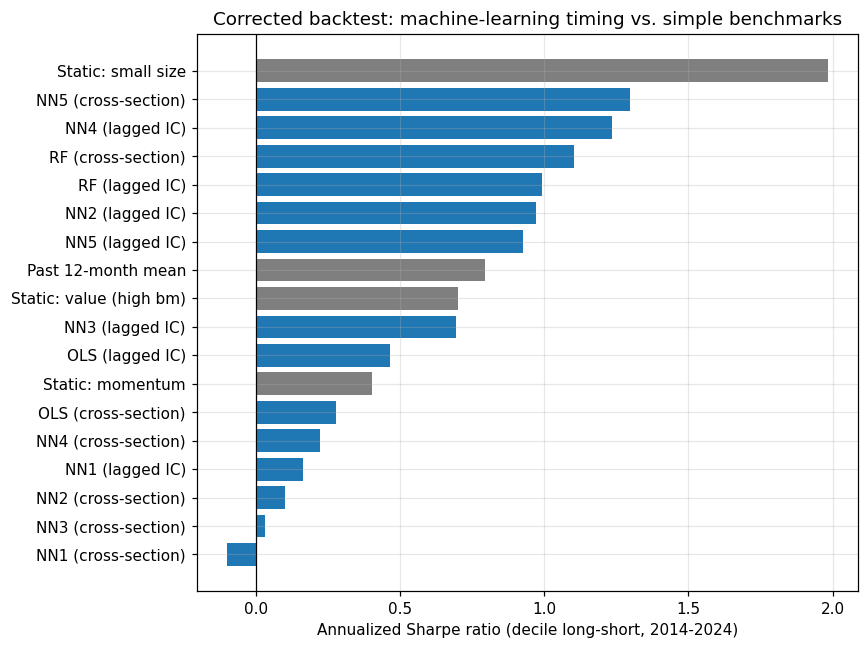

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
order = table['Sharpe ratio'].drop('Perfect foresight').sort_values()
colors = ['tab:gray' if n.startswith(('Static', 'Past')) else 'tab:blue' for n in order.index]
ax.barh(order.index, order.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Annualized Sharpe ratio (decile long-short, 2014-2024)')
ax.set_title('Corrected backtest: machine-learning timing vs. simple benchmarks')
plt.tight_layout()
fig.savefig(FIG_DIR / 'strategy_sharpe.png', dpi=150)
plt.show()

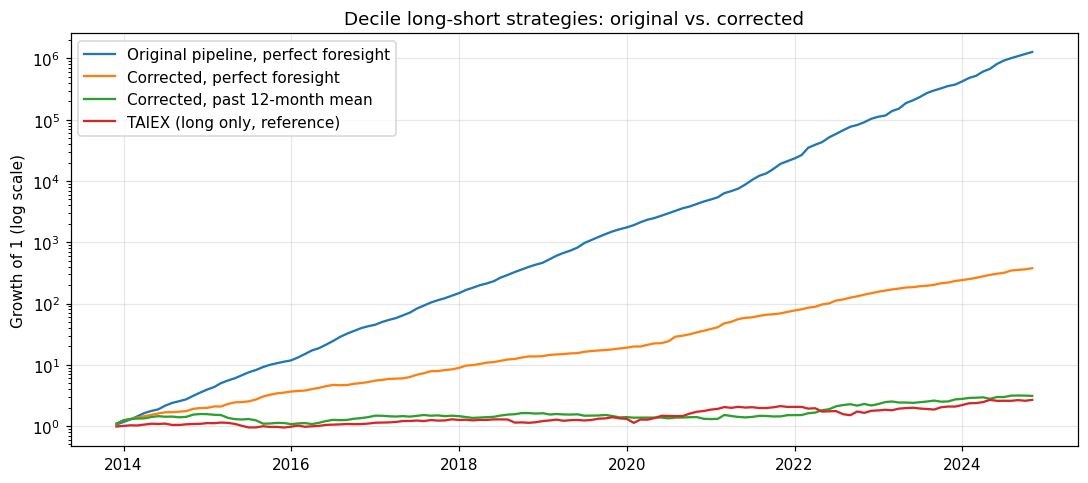

In [13]:
r_orig, _ = backtest(ic_original.loc[TEST], original, groups=[10], simple=False)
# TAIEX returns are labelled by the month they are earned; align them with the formation month
market = pd.Series(twii.values[:len(TEST)], index=TEST)
compare = {
    'Original pipeline, perfect foresight': np.exp(r_orig[10].cumsum()),
    'Corrected, perfect foresight': (1 + returns['Perfect foresight']).cumprod(),
    'Corrected, past 12-month mean': (1 + returns['Past 12-month mean']).cumprod(),
    'TAIEX (long only, reference)': np.exp(market.cumsum()),
}
fig, ax = plt.subplots(figsize=(10, 4.5))
for label, wealth in compare.items():
    idx = pd.to_datetime(wealth.index, format='%Y/%m')
    ax.plot(idx, wealth.values, label=label)
ax.set_yscale('log')
ax.set_ylabel('Growth of 1 (log scale)')
ax.set_title('Decile long-short strategies: original vs. corrected')
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'original_vs_corrected.png', dpi=150)
plt.show()

## 5. Sensitivity to the number of groups

The original project reported results for 14 group counts, from deciles (10 groups) to a single stock on
each side (1,848 groups). Sharpe ratios for the benchmarks and the two best models:

In [11]:
best_models = table.drop(['Perfect foresight', 'Past 12-month mean', 'Static: value (high bm)',
                          'Static: small size', 'Static: momentum']).nlargest(2, 'Sharpe ratio').index
rows = {}
for name in ['Perfect foresight', 'Past 12-month mean', 'Static: small size', *best_models]:
    r, _ = backtest(strategies[name], fixed)
    rows[name] = {g: performance(r[g])['Sharpe ratio'] for g in r.columns}
pd.DataFrame(rows).T.round(2)

,10,20,50,100,184,205,231,264,308,370,462,616,924,1848
Perfect foresight,5.24,4.52,3.34,2.95,2.50,2.30,2.18,1.99,1.93,1.80,1.86,1.23,0.99,0.99
Past 12-month mean,0.79,0.87,0.72,0.82,0.57,0.54,0.48,0.57,0.60,0.49,0.48,0.30,0.14,0.14
Static: small size,1.98,2.22,2.17,2.11,1.93,1.89,1.84,1.73,1.63,1.31,1.24,1.03,0.69,0.69
NN5 (cross-section),1.30,1.31,1.14,1.09,1.07,1.03,0.98,0.95,1.03,0.99,0.89,0.70,0.40,0.40
NN4 (lagged IC),1.23,1.30,1.40,1.27,0.97,1.20,1.11,1.16,1.13,1.05,1.11,0.90,0.47,0.47


## 6. Export results

Aggregated results (monthly ICs, predictions, and strategy returns) are saved to `results/` as CSV files.
They contain no stock-level data.

In [12]:
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

# True monthly IC in the test period, corrected and original
pd.concat({'corrected': ic_fixed.loc[TEST], 'original': ic_original.loc[TEST]}, axis=1) \
    .to_csv(RESULTS_DIR / 'ic_true.csv', index_label='month')

# Predicted IC: one row per feature set, model, and month
frames = []
for features, preds in [('cross_section', preds_cross), ('lagged_ic', preds_lagged),
                        ('original_data', preds_original)]:
    for model, pred in preds.items():
        frames.append(pred.rename_axis('month').reset_index().assign(features=features, model=model))
pd.concat(frames)[['features', 'model', 'month', *FACTORS]] \
    .to_csv(RESULTS_DIR / 'ic_predicted.csv', index=False)

# Monthly decile long-short returns and the chosen factor (labelled by the month the portfolio is formed)
pd.DataFrame(returns).rename_axis('month').to_csv(RESULTS_DIR / 'strategy_returns.csv')
pd.DataFrame(picks).rename_axis('month').to_csv(RESULTS_DIR / 'chosen_factor.csv')

# Summary tables
table.rename_axis('strategy').to_csv(RESULTS_DIR / 'performance.csv')
r2_flat = r2.copy()
r2_flat.columns = [f'{measure} ({data})' for measure, data in r2.columns]
r2_flat.to_csv(RESULTS_DIR / 'oos_r2.csv')
pd.DataFrame(orig_rows).T.rename_axis('model').to_csv(RESULTS_DIR / 'original_reproduction.csv')

# Sharpe ratio for every group count
sensitivity = {}
for name in strategies:
    r, _ = backtest(strategies[name], fixed)
    sensitivity[name] = {g: performance(r[g])['Sharpe ratio'] for g in r.columns}
pd.DataFrame(sensitivity).T.rename_axis('strategy').to_csv(RESULTS_DIR / 'sharpe_by_group_count.csv')

print('\n'.join(sorted(p.name for p in RESULTS_DIR.iterdir())))

chosen_factor.csv
ic_predicted.csv
ic_true.csv
oos_r2.csv
original_reproduction.csv
performance.csv
sharpe_by_group_count.csv
strategy_returns.csv


## 7. Conclusions

- **The original results came from the momentum alignment error.** Matched with a return inside its own
  window, momentum had a mean IC of 0.304 and was positive in every month. Correctly aligned, its mean IC is
  0.002 and it is positive in 51% of months. Reproducing the original pipeline gives annual returns above
  100% and Sharpe ratios of 7 to 10.5 for the models that keep choosing momentum (RF and NN5 choose it in all
  132 months).
- **None of the models forecasts the IC well.** Out-of-sample R² is negative for OLS and every neural network,
  and only slightly positive for the random forest (about 0.05), which is shallow (depth 3) and stays close to
  the average. With 1,848 cross-sectional features and about 160 monthly observations, the neural networks
  are far worse than predicting zero.
- **Timing does not beat a static strategy.** The best models reach Sharpe ratios of 1.2 to 1.4 (NN5 and RF
  with cross-sectional features, NN4 with lagged ICs), but always holding the small-size factor reaches 1.98
  without any forecasting. The better models mostly choose size or book-to-market, so their returns largely
  reflect exposure to those factors rather than successful timing.
- **The small-size result itself is likely overstated.** The sample contains only companies still listed in
  December 2024, so small firms that later delisted are missing, and transaction costs are ignored.
- **Perfect foresight (Sharpe 5.2) shows the potential of factor timing**, which none of the forecasts come
  close to.